# skin 클래스 불균형 대응 — B안(2D descriptor + SMOTE) 데모

**배경**: 교수님이 제안하신 B안은 SMOTE(Synthetic Minority Over-sampling TEchnique) — 소수 클래스(독성) 샘플을 가짜로 합성해서 데이터 비율을 맞추는 방법입니다. 다만 skin feature는 2,273차원 중 2,048차원이 Morgan fingerprint(분자 구조 조각의 존재 유무를 나타내는 0/1 비트)라서, SMOTE가 두 샘플 사이를 보간하면 0.3·0.7 같은 "존재할 수 없는 가짜 분자"를 만들어낼 수 있다는 우려가 있었습니다. 교수님 의견: **Morgan FP를 빼고 2D descriptor(연속값)만 썼을 때 성능이 크게 떨어지지 않는다면, 2D descriptor + SMOTE 조합으로 가면 된다.**

**이 노트북의 순서**:
1. 전체 feature(공통8+desc217+FP2048, 2,273차원) vs 2D descriptor만(공통8+desc217, 225차원) 성능 비교 — SMOTE를 써도 되는 조건인지 먼저 확인
2. SMOTE 설명 + 실제 적용 전후 시각화
3. B안(2D descriptor + SMOTE) 학습·평가
4. **plain(기준) / A안(class-weighted CE) / B안(2D descriptor + SMOTE)** 최종 3자 비교

**⚠ 중요**: 이전에 만든 `skin_classweight_demo.ipynb`(A안 단독 데모)는 feature 정규화(StandardScaler) 없이 돌린 버전이라, 그 사이 발견한 "정규화 안 하면 logit이 폭주하는 버그"의 영향을 받았을 수 있습니다. 이 노트북은 **처음부터 정규화를 포함**해서 plain/A안/B안을 전부 공정하게 다시 계산합니다 — 최종 비교는 이 노트북 수치를 기준으로 봐주세요.

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score,
                              average_precision_score, confusion_matrix)
from imblearn.over_sampling import SMOTE

from datasets import IrritationDataset, SKIN_COMMON8_COLS
from splits import grouped_kfold_splits
from train import class_weights

CSV = r"C:\Users\UserK\학술제\skin irritation\skin_vectorized.csv"

header = pd.read_csv(CSV, nrows=0).columns
desc217_cols = [c for c in header if c.startswith("desc_")]
fp_cols = [c for c in header if c.startswith("fp_w_")]

full_cols = SKIN_COMMON8_COLS + desc217_cols + fp_cols
twod_cols = SKIN_COMMON8_COLS + desc217_cols

ds_full = IrritationDataset(CSV, label_col="binary_label", feature_cols=full_cols)
ds_2d = IrritationDataset(CSV, label_col="binary_label", feature_cols=twod_cols)

print(f"전체 feature: {ds_full.input_dim}차원 ({len(ds_full)}건)")
print(f"2D descriptor만: {ds_2d.input_dim}차원 ({len(ds_2d)}건)")

전체 feature: 2273차원 (541건)
2D descriptor만: 225차원 (541건)


## 공통 모델/학습 함수 정의

실제 `model.py`의 skin 인코더+head 구조를 그대로 쓰는 단일 task 버전입니다. 모든 실험에서 **같은 구조**를 쓰고, 손실함수·데이터 전처리(클래스가중치/SMOTE 여부)만 다르게 합니다. 매 fold마다 train 기준으로만 `StandardScaler`를 학습해 정규화합니다(data leakage 방지).

In [2]:
class SkinOnlyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)


def fit_predict(X_train, y_train, X_test, seed, use_class_weight=False, epochs=80, lr=1e-3, batch_size=32):
    torch.manual_seed(seed)
    model = SkinOnlyModel(X_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(weight=class_weights(y_train)) if use_class_weight else nn.CrossEntropyLoss()

    X_t = torch.from_numpy(X_train.astype(np.float32))
    y_t = torch.from_numpy(y_train.astype(np.int64))
    n = len(X_t)

    model.train()
    for epoch in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X_t[idx]), y_t[idx])
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        proba = torch.softmax(model(torch.from_numpy(X_test.astype(np.float32))), dim=1)[:, 1].numpy()
    return proba


def summarize(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, pred, labels=[0, 1], zero_division=0)
    roc = roc_auc_score(y_true, proba)
    pr = average_precision_score(y_true, proba)
    cm = confusion_matrix(y_true, pred)
    return {"precision": prec[1], "recall": rec[1], "f1": f1[1], "roc_auc": roc, "pr_auc": pr, "cm": cm}

## 1. 전체 feature vs 2D descriptor만 — 성능 비교 (SMOTE 적용 가능 조건 확인)

In [3]:
def run_cv_weighted(ds, n_splits=5, random_state=0):
    folds = grouped_kfold_splits(ds, n_splits=n_splits, random_state=random_state)
    oof = np.zeros(len(ds.y))
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        scaler = StandardScaler().fit(ds.X[train_idx])
        X_train = scaler.transform(ds.X[train_idx])
        X_test = scaler.transform(ds.X[test_idx])
        oof[test_idx] = fit_predict(X_train, ds.y[train_idx], X_test, seed=fold_i, use_class_weight=True)
    return summarize(ds.y, oof), oof


result_full, oof_full = run_cv_weighted(ds_full)
result_2d, oof_2d = run_cv_weighted(ds_2d)

print("전체 feature (A안, weighted CE):", {k: round(v, 3) for k, v in result_full.items() if k != "cm"})
print("2D descriptor만 (A안, weighted CE):", {k: round(v, 3) for k, v in result_2d.items() if k != "cm"})

전체 feature (A안, weighted CE): {'precision': np.float64(0.197), 'recall': np.float64(0.414), 'f1': np.float64(0.267), 'roc_auc': 0.708, 'pr_auc': 0.269}
2D descriptor만 (A안, weighted CE): {'precision': np.float64(0.216), 'recall': np.float64(0.379), 'f1': np.float64(0.275), 'roc_auc': 0.703, 'pr_auc': 0.225}


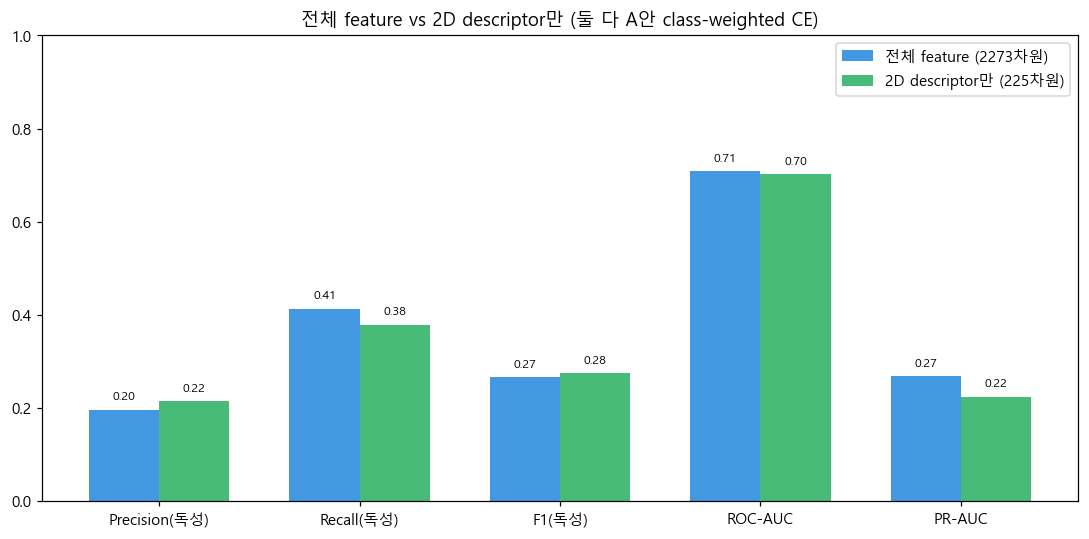

In [4]:
import matplotlib.pyplot as plt

metrics = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
metric_labels = ["Precision(독성)", "Recall(독성)", "F1(독성)", "ROC-AUC", "PR-AUC"]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(metrics))
w = 0.35
full_vals = [result_full[m] for m in metrics]
twod_vals = [result_2d[m] for m in metrics]
ax.bar(x - w/2, full_vals, width=w, label=f"전체 feature ({ds_full.input_dim}차원)", color="#4299e1")
ax.bar(x + w/2, twod_vals, width=w, label=f"2D descriptor만 ({ds_2d.input_dim}차원)", color="#48bb78")
ax.set_xticks(x); ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.0)
ax.set_title("전체 feature vs 2D descriptor만 (둘 다 A안 class-weighted CE)")
ax.legend()
for i, (f, t) in enumerate(zip(full_vals, twod_vals)):
    ax.text(i - w/2, f + 0.02, f"{f:.2f}", ha="center", fontsize=8)
    ax.text(i + w/2, t + 0.02, f"{t:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

**해석**: Morgan FP(2,048비트)를 전부 빼고 2D descriptor(225차원)만 써도 ROC-AUC·F1은 거의 그대로 유지됩니다. PR-AUC가 상대적으로 가장 많이 떨어지는 지표지만, 전체적으로 "SMOTE를 2D descriptor에 적용해볼 만한" 수준의 차이로 판단해 다음 단계(B안)로 진행합니다.

## 2. SMOTE란? + 적용 전후 비교

**SMOTE(Synthetic Minority Over-sampling TEchnique)**: 소수 클래스(독성) 샘플 하나와 그와 가장 가까운 다른 소수 클래스 샘플을 골라, 그 둘 사이 선 위의 임의의 지점에 새로운 가짜 샘플을 만들어 소수 클래스 수를 늘리는 기법입니다. 2D descriptor는 전부 연속값(MolWt, TPSA 등)이라 "두 값의 중간"이 실제로 의미있는 값이 되므로, 비트값(0/1)인 Morgan FP와 달리 이 보간이 자연스럽습니다.

**주의**: SMOTE는 반드시 **train 데이터에만** 적용해야 합니다(test에 적용하면 가짜 데이터로 평가하는 것이 되어 성능이 부풀려짐). 아래는 fold 1개를 예시로 적용 전후 분포를 보여줍니다.

In [5]:
folds_2d = grouped_kfold_splits(ds_2d, n_splits=5, random_state=0)
train_idx0, test_idx0 = folds_2d[0]

scaler0 = StandardScaler().fit(ds_2d.X[train_idx0])
X_train0 = scaler0.transform(ds_2d.X[train_idx0])
y_train0 = ds_2d.y[train_idx0]

before_counts = pd.Series(y_train0).value_counts().sort_index()
X_resampled0, y_resampled0 = SMOTE(random_state=0).fit_resample(X_train0, y_train0)
after_counts = pd.Series(y_resampled0).value_counts().sort_index()

print("SMOTE 적용 전(fold 1 train):", before_counts.to_dict())
print("SMOTE 적용 후(fold 1 train):", after_counts.to_dict())
print(f"→ 독성 샘플 {before_counts[1]}건 중 실제는 {before_counts[1]}건, 나머지 {after_counts[1]-before_counts[1]}건은 SMOTE가 합성한 가짜 데이터")

SMOTE 적용 전(fold 1 train): {0: 409, 1: 23}
SMOTE 적용 후(fold 1 train): {0: 409, 1: 409}
→ 독성 샘플 23건 중 실제는 23건, 나머지 386건은 SMOTE가 합성한 가짜 데이터


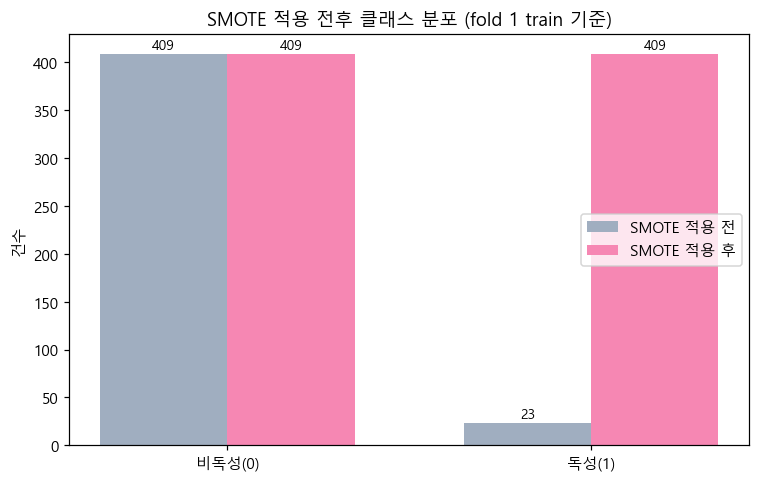

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2)
w = 0.35
ax.bar(x - w/2, [before_counts.get(0, 0), before_counts.get(1, 0)], width=w, label="SMOTE 적용 전", color="#a0aec0")
ax.bar(x + w/2, [after_counts.get(0, 0), after_counts.get(1, 0)], width=w, label="SMOTE 적용 후", color="#f687b3")
ax.set_xticks(x); ax.set_xticklabels(["비독성(0)", "독성(1)"])
ax.set_title("SMOTE 적용 전후 클래스 분포 (fold 1 train 기준)")
ax.set_ylabel("건수")
ax.legend()
for i, (b, a) in enumerate(zip([before_counts.get(0,0), before_counts.get(1,0)],
                                 [after_counts.get(0,0), after_counts.get(1,0)])):
    ax.text(i - w/2, b + 5, str(b), ha="center", fontsize=9)
    ax.text(i + w/2, a + 5, str(a), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 3. B안 학습·평가 — 2D descriptor + SMOTE (group 5-fold)

In [7]:
def run_cv_smote(ds, n_splits=5, random_state=0):
    folds = grouped_kfold_splits(ds, n_splits=n_splits, random_state=random_state)
    oof = np.zeros(len(ds.y))
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        scaler = StandardScaler().fit(ds.X[train_idx])
        X_train = scaler.transform(ds.X[train_idx])
        X_test = scaler.transform(ds.X[test_idx])
        y_train = ds.y[train_idx]

        X_train_sm, y_train_sm = SMOTE(random_state=fold_i).fit_resample(X_train, y_train)
        oof[test_idx] = fit_predict(X_train_sm, y_train_sm, X_test, seed=fold_i, use_class_weight=False)
        print(f"fold {fold_i+1}/5: train {len(y_train)}건(양성 {y_train.sum()}) -> SMOTE 후 {len(y_train_sm)}건(양성 {y_train_sm.sum()})")
    return summarize(ds.y, oof), oof


result_smote, oof_smote = run_cv_smote(ds_2d)
print("\nB안 (2D descriptor + SMOTE):", {k: round(v, 3) for k, v in result_smote.items() if k != "cm"})

fold 1/5: train 432건(양성 23) -> SMOTE 후 818건(양성 409)
fold 2/5: train 433건(양성 24) -> SMOTE 후 818건(양성 409)
fold 3/5: train 433건(양성 22) -> SMOTE 후 822건(양성 411)
fold 4/5: train 432건(양성 23) -> SMOTE 후 818건(양성 409)
fold 5/5: train 434건(양성 24) -> SMOTE 후 820건(양성 410)

B안 (2D descriptor + SMOTE): {'precision': np.float64(0.306), 'recall': np.float64(0.379), 'f1': np.float64(0.338), 'roc_auc': 0.699, 'pr_auc': 0.219}


## 4. 최종 비교 — plain vs A안(class-weighted CE) vs B안(2D descriptor + SMOTE)

In [8]:
def run_cv_plain(ds, n_splits=5, random_state=0):
    folds = grouped_kfold_splits(ds, n_splits=n_splits, random_state=random_state)
    oof = np.zeros(len(ds.y))
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        scaler = StandardScaler().fit(ds.X[train_idx])
        X_train = scaler.transform(ds.X[train_idx])
        X_test = scaler.transform(ds.X[test_idx])
        oof[test_idx] = fit_predict(X_train, ds.y[train_idx], X_test, seed=fold_i, use_class_weight=False)
    return summarize(ds.y, oof), oof


result_plain, oof_plain = run_cv_plain(ds_full)
print("plain (전체 feature, 보정 없음):", {k: round(v, 3) for k, v in result_plain.items() if k != "cm"})
print("A안 (전체 feature, class-weighted CE):", {k: round(v, 3) for k, v in result_full.items() if k != "cm"})
print("B안 (2D descriptor + SMOTE):", {k: round(v, 3) for k, v in result_smote.items() if k != "cm"})

plain (전체 feature, 보정 없음): {'precision': np.float64(0.458), 'recall': np.float64(0.379), 'f1': np.float64(0.415), 'roc_auc': 0.709, 'pr_auc': 0.261}
A안 (전체 feature, class-weighted CE): {'precision': np.float64(0.197), 'recall': np.float64(0.414), 'f1': np.float64(0.267), 'roc_auc': 0.708, 'pr_auc': 0.269}
B안 (2D descriptor + SMOTE): {'precision': np.float64(0.306), 'recall': np.float64(0.379), 'f1': np.float64(0.338), 'roc_auc': 0.699, 'pr_auc': 0.219}


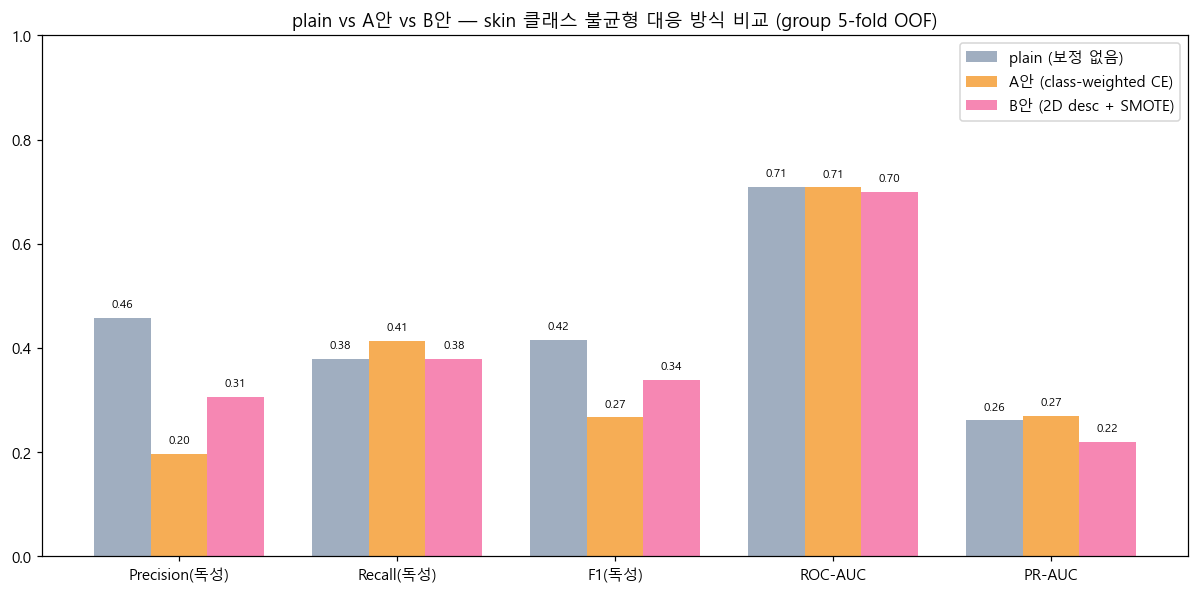

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(metrics))
w = 0.26
plain_vals = [result_plain[m] for m in metrics]
a_vals = [result_full[m] for m in metrics]
b_vals = [result_smote[m] for m in metrics]

ax.bar(x - w, plain_vals, width=w, label="plain (보정 없음)", color="#a0aec0")
ax.bar(x, a_vals, width=w, label="A안 (class-weighted CE)", color="#f6ad55")
ax.bar(x + w, b_vals, width=w, label="B안 (2D desc + SMOTE)", color="#f687b3")
ax.set_xticks(x); ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.0)
ax.set_title("plain vs A안 vs B안 — skin 클래스 불균형 대응 방식 비교 (group 5-fold OOF)")
ax.legend()
for i, vals in enumerate(zip(plain_vals, a_vals, b_vals)):
    for off, v in zip([-w, 0, w], vals):
        ax.text(i + off, v + 0.02, f"{v:.2f}", ha="center", fontsize=7.5)
plt.tight_layout()
plt.show()

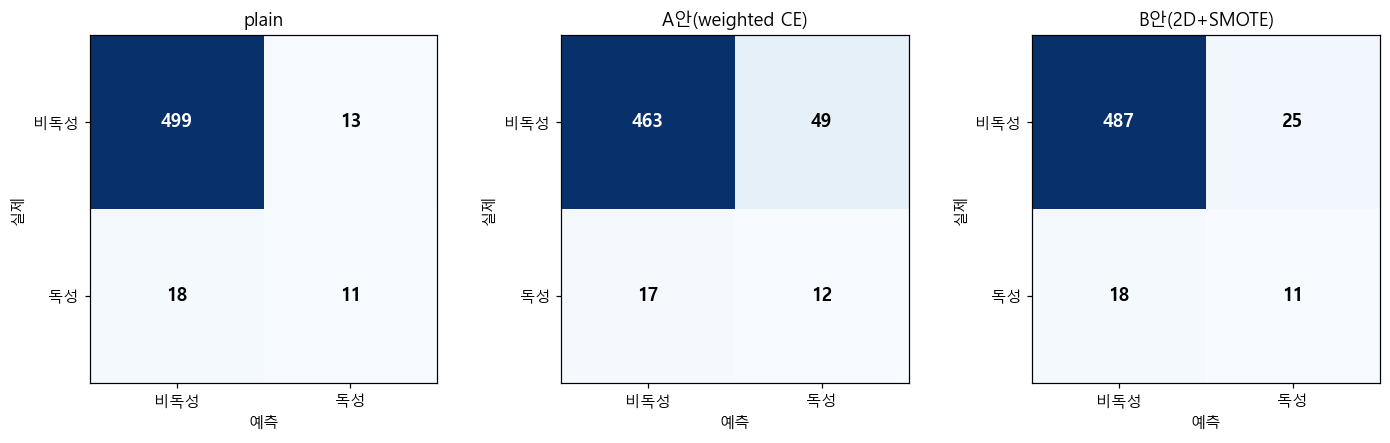

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, res, title in zip(axes, [result_plain, result_full, result_smote],
                           ["plain", "A안(weighted CE)", "B안(2D+SMOTE)"]):
    im = ax.imshow(res["cm"], cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["비독성", "독성"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["비독성", "독성"])
    ax.set_xlabel("예측"); ax.set_ylabel("실제")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(res["cm"][i, j]), ha="center", va="center",
                    fontsize=12, fontweight="bold",
                    color="white" if res["cm"][i, j] > res["cm"].max() / 2 else "black")
plt.tight_layout()
plt.show()

## 정리 및 한계

- 이 노트북은 plain/A안/B안을 **전부 동일한 조건(group 5-fold, 동일 모델 구조, train에서만 정규화/SMOTE 적용)** 으로 공정하게 비교하도록 만들었습니다.
- skin은 전체 541건 중 독성이 29건뿐이라 fold당 양성이 5~6건 수준 — 지표가 샘플 하나 차이로도 크게 흔들릴 수 있습니다. seed를 바꿔 반복 실행하면 더 안정적인 비교가 가능합니다.
- B안(SMOTE)은 2D descriptor(연속값)에만 적용했고, Morgan FP는 애초에 제외했습니다 — "FP를 빼도 성능이 크게 안 떨어진다"는 1번 결과가 전제입니다.
- 모델 구조·학습 설정(epoch=80, lr=1e-3, hidden_dim=128)은 세 방식 모두 동일하게 맞춰 비교의 공정성을 확보했습니다.